# 07 Eindmodel: 3 tot 5 onderbouwde leesadviezen

Dit notebook laat het eindresultaat zien zoals de opdracht vraagt:

1. het **studentprofiel analyseren** (interesses, leesniveau, voorkeuren),
2. het leesmateriaal **vergelijken** met het profiel,
3. **3 tot 5** gepersonaliseerde aanbevelingen,
4. **uitleg**: waarom past dit bij de student? Die uitleg is een kort verhaaltje van Bo, opgebouwd uit dezelfde signalen
   die het model gebruikte (onderwerp, niveau, leestijd, eerdere favorieten en studenten met dezelfde smaak).

Daarna train ik het eindmodel op alle data en sla ik het op voor de API.

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from reading_coach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from reading_coach.data_cleaning import load_processed
from reading_coach.features import StudentProfile
from reading_coach.hybrid import HybridRecommender

materials, students, interactions = load_processed()
model = HybridRecommender().fit(materials, students, interactions)
path = model.save()
print("Model opgeslagen in", path)

Model opgeslagen in /sessions/rcw-01gykshk1wbymnm8nqvu5w79/work/ai/models/hybrid_model.joblib


## 1. Een student uit de dataset

In [3]:
def show_advice(student_id: str, n: int = 5) -> None:
    row = students[students["student_id"] == student_id].iloc[0]
    profile = model.profile_of(row)
    own = interactions[interactions["student_id"] == student_id]
    history = dict(zip(own["catalog_code"], own["preference_score"]))
    print(f"Student {student_id}: niveau {row['reading_level']}, taal {row['cefr_level']}, interesses {row['interests'].replace(';', ', ')}")
    print(f"Voorkeur {row['preferred_type']}, genre {row['preferred_genre']}, max {row['max_minutes']} minuten,"
          f" {int(own['positive'].sum())} van {len(own)} eerdere interacties positief")
    print()
    for number, item in enumerate(model.recommend(profile, history, n=n), start=1):
        print(f"{number}. {item.title} ({item.type}, {item.level}), score {item.score:.2f}")
        print(f"   {item.motivation}")
    print()

for student_id in ["S001", "S004", "S042"]:
    show_advice(student_id)

Student S001: niveau 2F, taal C1, interesses kunstmatige intelligentie, relaties
Voorkeur boek, genre informatief, max 60 minuten, 7 van 20 eerdere interacties positief

1. Een echte man (boek, 2F), score 0.85
   Omdat je van relaties houdt, denk ik dat dit echt iets voor jou is. Het is een boek op 2F, precies jouw niveau, en al is het langer dan je wilde, in ongeveer 3 keer heb je het uit.
2. Wat is een rechtsstaat? (online-artikel, 2F-3F), score 0.83
   Dit gaat over rechtsstaat en grondrechten, en ik denk dat het goed bij je past. Het is een online artikel op 2F-3F, net iets uitdagender dan 2F en dus goed om van te groeien, en met ongeveer 10 minuten leestijd past het in de tijd die je hebt.
3. De fout (boek, 2F), score 0.84
   Omdat je van relaties houdt, denk ik dat dit echt iets voor jou is. Het is een boek op 2F, precies jouw niveau, en al is het langer dan je wilde, in ongeveer 5 keer heb je het uit. Bovendien vonden lezers met een smaak zoals die van jou het goed.
4. Hoe werkt

1. Transparantie-eisen voor AI: wat betekent dit voor u? (online-artikel, 3F+), score 0.80
   Je houdt van kunstmatige intelligentie, en precies daar gaat dit over. Het is een online artikel op 3F+, net iets uitdagender dan 3F en dus goed om van te groeien, en met ongeveer 15 minuten leestijd past het in de tijd die je hebt. Bovendien vonden lezers met een smaak zoals die van jou het goed.
2. Schulden in Nederland: de stand van zaken (online-artikel, 3F), score 0.79
   Dit lijkt op wat je eerder goed vond. Het is een online artikel op 3F, precies jouw niveau, en met ongeveer 20 minuten leestijd past het in de tijd die je hebt.
3. Vanaf 2 augustus wordt duidelijker of het AI is of echt (online-artikel, 3F), score 0.80
   Het gaat over kunstmatige intelligentie, en daar lees jij graag over. Het is een online artikel op 3F, precies jouw niveau, en met ongeveer 10 minuten leestijd past het in de tijd die je hebt. Bovendien vonden lezers met een smaak zoals die van jou het goed.
4. Zorgen o

## 2. Een nieuwe student zonder geschiedenis (cold start)
Zo komt een profiel uit de Fastify app binnen. Zonder geschiedenis leunt het model op inhoud en profiel.

In [4]:
new_student = StudentProfile(
    reading_level="2F",
    interests=["sport", "vriendschap", "humor"],
    material_types=["boek"],
    preferred_genre="fictie",
    max_minutes=90,
)
for item in model.recommend(new_student, n=3):
    print(f"{item.title} ({item.level}): {item.motivation}")

Een echte man (2F): Omdat je van humor houdt, denk ik dat dit echt iets voor jou is. Het is een boek op 2F, precies jouw niveau, en al is het langer dan je wilde, in ongeveer 2 keer heb je het uit.
Wat Floris niet wist (2F): Het gaat over vriendschap, en daar lees jij graag over. Het is een boek op 2F, precies jouw niveau, en al is het langer dan je wilde, in ongeveer 5 keer heb je het uit.
Imke (2F): Je houdt van humor, en precies daar gaat dit over. Het is een boek op 2F, precies jouw niveau, en al is het langer dan je wilde, in ongeveer 4 keer heb je het uit.


## 3. Het advies verandert met de geschiedenis
De student leest en waardeert het eerste advies. Daarna schuift het advies op.

In [5]:
first = model.recommend(new_student, n=5)
history = {first[0].catalog_code: 5.0, first[1].catalog_code: 1.0}
print("Gelezen en leuk:", first[0].title, "| afgewezen:", first[1].title)
for item in model.recommend(new_student, history, n=5):
    print(f"  {item.title} ({item.score:.2f})")

Gelezen en leuk: Een echte man | afgewezen: Wat Floris niet wist


  Heartstopper 3 (0.89)
  De familie Blues (0.88)
  De open era (0.88)
  De roadtrip (0.87)
  De blauwe stilte (0.87)


## 4. Wat ziet de docent?
Voor transparantie kan de docent per advies de onderliggende kenmerken zien, en welke signalen in het algemeen het zwaarst wegen.

In [6]:
item = model.recommend(new_student, n=1)[0]
from reading_coach.features import FEATURE_LABELS
print(item.reasons)
pd.Series(item.features).rename(index=FEATURE_LABELS).to_frame(item.title)

['Het gaat over humor, iets waar je interesse in hebt.', 'Het niveau (2F) past precies bij jouw leesniveau (2F).', 'Het is een boek, het soort tekst dat je graag leest.', 'Het genre (fictie) is jouw voorkeur.']


,Een echte man
Niveauverschil (materiaal min student),0.0000
Afstand tot eigen niveau,0.0000
Past bij voorkeur materiaaltype,1.0000
Past bij voorkeur genre,1.0000
Tekstovereenkomst met interesses,0.0750
Aantal interesses in de tekst,1.0000
Lijkt op eerder gewaardeerd materiaal,0.0000
Leestijd ten opzichte van maximum (log),1.0949
Binnen maximale leestijd,0.0000
Juiste taal,1.0000


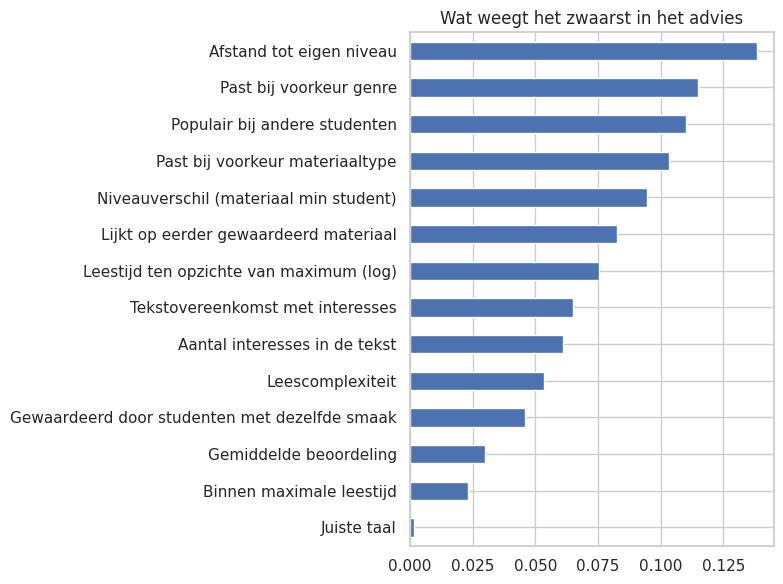

In [7]:
model.feature_importance.rename(index=FEATURE_LABELS).plot.barh(figsize=(8, 6), title="Wat weegt het zwaarst in het advies")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Volgende stap: koppelen aan de app

Start de API (`uvicorn api.main:app --port 8000`) en laat de Fastify backend `POST /api/recommendations` aanroepen met het
leesprofiel en de leeslijst van de student. Zie `docs/koppeling-fastify.md`.